# Food Delivery Time Prediction Using Three Kaggle Datasets
**Aaditi Gaikwad | PRN 23070521052**  
**Predictive Analytics | Submitted to Dr. Deepak Asudani**

## 1. Problem identification
Predict the recorded food delivery duration in minutes. This is supervised regression. We use three datasets to study whether the same KDD workflow can build useful models under different available information.

- **Dataset A:** [Den_Kuznetz, Food Delivery Time Prediction](https://www.kaggle.com/datasets/denkuznetz/food-delivery-time-prediction), version 1. 1,000 original orders with weather, traffic, distance and courier experience.
- **Dataset B:** [Rajat Kumar, Food Delivery Time](https://www.kaggle.com/datasets/rajatkumar30/food-delivery-time), version 1. 45,593 original rows with locations, courier IDs, age and order/vehicle types.

All three datasets actively enter training, model selection and final testing. **They are separate experiments, not concatenated or joined.** There is no shared order key, their columns differ, and the precise target start/end events are not documented consistently. No cross-dataset transfer or pooled performance claim is made.

## 2. Literature and prediction boundary
Garg et al. (2025), https://arxiv.org/abs/2503.15177, motivate comparing regression approaches. Wen et al. (2023), https://arxiv.org/abs/2309.01194, distinguish time prediction from route prediction. These summaries use abstracts, not reproduced experiments.

For A, exclude ID and recorded preparation duration, which may become known only after ordering. For B, exclude IDs from predictors, retain courier ID only for splitting, and exclude courier rating because its measurement time is unspecified. Use distance derived from coordinates, age, order type and vehicle. This is an estimate conditional on an assigned courier and supplied context, not a validated pre-assignment/live ETA service. The exact recorded duration definitions require operational verification.

## 3. Predetermined evaluation plan
Seed 42. A: random 80/20 order split and five shuffled validation folds. B: about 80/20 **courier-group** split and five courier-group validation folds, so a courier never appears on both sides. Select the lowest validation MAE from four fixed candidates. Evaluate the selected candidate and median baseline on the untouched test set. Do not choose features/settings from test results.

Setup: Python 3.12; install requirements.txt; run all cells from this folder. The datasets are bundled locally. Attribution and license links are in data/DATA_SOURCES.md.

### Dataset C: FoodHub orders
Third Kaggle source: **Ahsan Raza, NYC Restaurants Data - Food Ordering and Delivery**, version 1.
https://www.kaggle.com/datasets/ahsan81/food-ordering-and-delivery-app-dataset
The raw file contains 1,898 orders, 9 columns and 178 restaurants. Kaggle metadata lists CC0: Public Domain. The target `delivery_time` measures the delivery stage, excluding the separately recorded preparation time. We do not add the two durations or claim identical target definitions across sources.

C uses order cost, cuisine and weekday/weekend. It excludes order/customer IDs, restaurant name as a predictor, post-order rating and actual preparation time. Restaurant name defines the holdout and validation groups. About 20% of restaurants form the holdout and the remainder support five GroupKFold validation folds. No restaurant crosses a training/validation boundary. Customers may order from more than one restaurant, so this tests unseen restaurants, not unseen customers.


In [1]:
import os
os.environ['OMP_NUM_THREADS']='2'
from pathlib import Path
import json, hashlib, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, KFold, GroupShuffleSplit, GroupKFold
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits
import joblib
from features import prepare_features, SCHEMAS
ROOT=Path.cwd(); RESULTS=ROOT/'results'; RESULTS.mkdir(exist_ok=True)
(ROOT/'models').mkdir(exist_ok=True)
SEED=42
files={'A':ROOT/'data/dataset_a/Food_Delivery_Times.csv','B':ROOT/'data/dataset_b/deliverytime.csv','C':ROOT/'data/dataset_c/food_order.csv'}
versions={p:importlib.metadata.version(p) for p in ['numpy','pandas','scipy','scikit-learn','matplotlib','joblib','nbformat','nbclient','ipykernel','threadpoolctl']}
print('Python',platform.python_version());display(pd.Series(versions,name='Version'))
raw={key:pd.read_csv(path) for key,path in files.items()}
assert raw['A'].shape==(1000,9) and raw['B'].shape==(45593,11) and raw['C'].shape==(1898,9)

Python 3.12.14


numpy             2.5.4
pandas            3.0.6
scipy            1.18.1
scikit-learn      1.9.1
matplotlib       3.11.2
joblib            1.6.0
nbformat         5.11.1
nbclient         0.11.0
ipykernel         7.4.0
threadpoolctl     3.7.0
Name: Version, dtype: str

## 4. Data understanding and quality rules
Keep raw CSVs unchanged. Remove **all rows with repeated order IDs** from B, because the same ID has potentially conflicting records; do not arbitrarily retain one. The exclusion log records their source-row positions. Missing or non-positive target values are excluded rather than imputed.

For B, calculate great-circle (Haversine) distance from the coordinate pairs. This is straight-line distance, **not road distance**. Coordinates must be nonzero and in valid latitude/longitude ranges. A derived distance above 100 km is treated as unavailable under a declared food-delivery plausibility rule. We do not guess corrected signs. Age outside 18–80 becomes missing. These are fixed input-only rules, applied equally during inference; no target-guided outlier trimming occurs. Rows with bad inputs remain for training-fold imputation. Raw IDs and ratings do not enter the model.

Numeric imputation uses the training median plus missing-value indicators, followed by scaling. Categories use Unknown plus one-hot encoding. All fitted transformations belong to a pipeline and are learned separately inside each training fold.

For C, retain all valid positive-target orders and check unique order IDs. The selected three inputs have no missing values in this file, but still use the same training-fold preprocessing pipeline. Exclude post-order rating and actual preparation duration to keep the prediction boundary explicit. Restaurant names define split groups only. Raw data stay unchanged.


In [2]:
experiments={}; audits={}
for key,d in raw.items():
    idcol={'A':'Order_ID','B':'ID','C':'order_id'}[key]
    target={'A':'Delivery_Time_min','B':'Time_taken(min)','C':'delivery_time'}[key]
    duplicated=d[idcol].duplicated(keep=False)
    invalid_y=pd.to_numeric(d[target],errors='coerce').isna() | (pd.to_numeric(d[target],errors='coerce')<=0)
    excluded=duplicated|invalid_y
    pd.DataFrame({'source_row':np.arange(len(d)), 'repeated_id':duplicated,'invalid_target':invalid_y}).loc[excluded].to_csv(RESULTS/f'{key}_excluded_rows.csv',index=False)
    clean=d.loc[~excluded].copy()
    X=prepare_features(clean,key); y=clean[target].astype(float)
    nums,cats=SCHEMAS[key]
    audit={'raw_rows':len(d),'raw_columns':len(d.columns),'raw_missing_cells':int(d.isna().sum().sum()),
           'repeated_id_rows_excluded':int(duplicated.sum()),'invalid_targets':int(invalid_y.sum()),
           'used_rows':len(clean),'feature_missing':{k:int(v) for k,v in X.isna().sum().items()},
           'sha256':hashlib.sha256(files[key].read_bytes()).hexdigest()}
    if key=='A':
        tr,te=train_test_split(np.arange(len(clean)),test_size=.2,random_state=SEED)
        folds=list(KFold(n_splits=5,shuffle=True,random_state=SEED).split(X.iloc[tr]))
        split_name='Random orders'
    else:
        group_col='Delivery_person_ID' if key=='B' else 'restaurant_name'
        groups=clean[group_col].str.strip()
        assert groups.notna().all()
        tr,te=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED).split(X,y,groups))
        folds=list(GroupKFold(n_splits=5).split(X.iloc[tr],y.iloc[tr],groups.iloc[tr]))
        assert set(groups.iloc[tr]).isdisjoint(set(groups.iloc[te]))
        for ft,fv in folds:assert set(groups.iloc[tr].iloc[ft]).isdisjoint(set(groups.iloc[tr].iloc[fv]))
        audit.update(group_type='courier' if key=='B' else 'restaurant',development_groups=int(groups.iloc[tr].nunique()),test_groups=int(groups.iloc[te].nunique()),group_overlap=0)
        split_name='Unseen couriers' if key=='B' else 'Unseen restaurants'
    assert set(clean.iloc[tr][idcol]).isdisjoint(set(clean.iloc[te][idcol]))
    audit.update(development_rows=len(tr),test_rows=len(te),split=split_name)
    partition=pd.DataFrame({'source_row':clean.index,'order_id':clean[idcol].values,'partition':'development'})
    partition.loc[te,'partition']='test'
    if key in ['B','C']:partition['group_id']=groups.values
    partition.to_csv(RESULTS/f'{key}_split.csv',index=False)
    experiments[key]={'clean':clean,'X':X,'y':y,'tr':tr,'te':te,'folds':folds,'nums':nums,'cats':cats,'target':target}
    audits[key]=audit
    print('Dataset',key);display(pd.Series(audit));display(X.head())
(RESULTS/'audits.json').write_text(json.dumps(audits,indent=2))

Dataset A


raw_rows                                                                  1000
raw_columns                                                                  9
raw_missing_cells                                                          120
repeated_id_rows_excluded                                                    0
invalid_targets                                                              0
used_rows                                                                 1000
feature_missing              {'Distance_km': 0, 'Courier_Experience_yrs': 3...
sha256                       9fc2f147a79ee7edec9cc19e70c35d460df713f942b4f1...
development_rows                                                           800
test_rows                                                                  200
split                                                            Random orders
dtype: object

,Distance_km,Courier_Experience_yrs,Weather,Traffic_Level,Time_of_Day,Vehicle_Type
0,7.93,1.0,Windy,Low,Afternoon,Scooter
1,16.42,2.0,Clear,Medium,Evening,Bike
2,9.52,1.0,Foggy,Low,Night,Scooter
3,7.44,1.0,Rainy,Medium,Afternoon,Scooter
4,19.03,5.0,Clear,Low,Morning,Bike


Dataset B


raw_rows                                                                 45593
raw_columns                                                                 11
raw_missing_cells                                                            0
repeated_id_rows_excluded                                                  259
invalid_targets                                                              0
used_rows                                                                45334
feature_missing              {'Straight_line_km': 4043, 'Delivery_person_Ag...
sha256                       a30359cd749f199eeb7bf1b915ff5d00b040d684ff52b6...
group_type                                                             courier
development_groups                                                        1056
test_groups                                                                264
group_overlap                                                                0
development_rows                                    

,Straight_line_km,Delivery_person_Age,Type_of_order,Type_of_vehicle
0,3.025149,37.0,Snack,motorcycle
1,20.183530,34.0,Snack,scooter
2,1.552758,23.0,Drinks,motorcycle
3,7.790401,38.0,Buffet,motorcycle
4,6.210138,32.0,Snack,scooter


Dataset C


raw_rows                                                                  1898
raw_columns                                                                  9
raw_missing_cells                                                            0
repeated_id_rows_excluded                                                    0
invalid_targets                                                              0
used_rows                                                                 1898
feature_missing              {'cost_of_the_order': 0, 'cuisine_type': 0, 'd...
sha256                       6cf8177f2e600dd642b1122d148cf2edfade950842b2a9...
group_type                                                          restaurant
development_groups                                                         142
test_groups                                                                 36
group_overlap                                                                0
development_rows                                    

,cost_of_the_order,cuisine_type,day_of_the_week
0,30.75,Korean,Weekend
1,12.08,Japanese,Weekend
2,12.23,Mexican,Weekday
3,29.20,American,Weekend
4,11.59,American,Weekday


1691

## 5. Development-only exploration
Inspect only development rows before model fitting. Compare duration distributions and distance relationships. Correlation is not causation. In B, distance calculation failures stay missing instead of dropping difficult orders. Different targets and populations mean the scores of A and B are separate benchmark results.

C exploration relates order cost to delivery-stage duration. Cost is not a distance measure. Restaurant-group evaluation differs from the courier-group and random-order evaluations.

,Distance_km,Courier_Experience_yrs,Weather,Traffic_Level,Time_of_Day,Vehicle_Type
count,800.00000,776.000000,778,781,776,800
unique,NaN,NaN,5,3,4,3
top,NaN,NaN,Clear,Medium,Morning,Bike
freq,NaN,NaN,375,311,240,397
mean,10.10055,4.606959,NaN,NaN,NaN,NaN
std,5.72590,2.946649,NaN,NaN,NaN,NaN
min,0.59000,0.000000,NaN,NaN,NaN,NaN
25%,5.13000,2.000000,NaN,NaN,NaN,NaN
50%,10.22000,5.000000,NaN,NaN,NaN,NaN
75%,14.94250,7.000000,NaN,NaN,NaN,NaN


count    800.000000
mean      57.053750
std       22.278774
min        8.000000
25%       41.000000
50%       56.000000
75%       71.000000
max      153.000000
Name: Delivery_Time_min, dtype: float64

,Straight_line_km,Delivery_person_Age,Type_of_order,Type_of_vehicle
count,33409.000000,36374.000000,36397,36397
unique,NaN,NaN,4,4
top,NaN,NaN,Snack,motorcycle
freq,NaN,NaN,9257,21072
mean,9.735405,29.530709,NaN,NaN
std,5.611060,5.688312,NaN,NaN
min,1.465067,20.000000,NaN,NaN
25%,4.657672,25.000000,NaN,NaN
50%,9.193028,29.000000,NaN,NaN
75%,13.680927,34.000000,NaN,NaN


count    36397.000000
mean        26.267522
std          9.371903
min         10.000000
25%         19.000000
50%         25.000000
75%         32.000000
max         54.000000
Name: Time_taken(min), dtype: float64

,cost_of_the_order,cuisine_type,day_of_the_week
count,1600.000000,1600,1600
unique,NaN,14,2
top,NaN,American,Weekend
freq,NaN,570,1139
mean,16.405481,NaN,NaN
std,7.433041,NaN,NaN
min,4.470000,NaN,NaN
25%,12.080000,NaN,NaN
50%,14.120000,NaN,NaN
75%,22.260000,NaN,NaN


count    1600.000000
mean       24.170625
std         4.966707
min        15.000000
25%        20.000000
50%        25.000000
75%        28.000000
max        33.000000
Name: delivery_time, dtype: float64

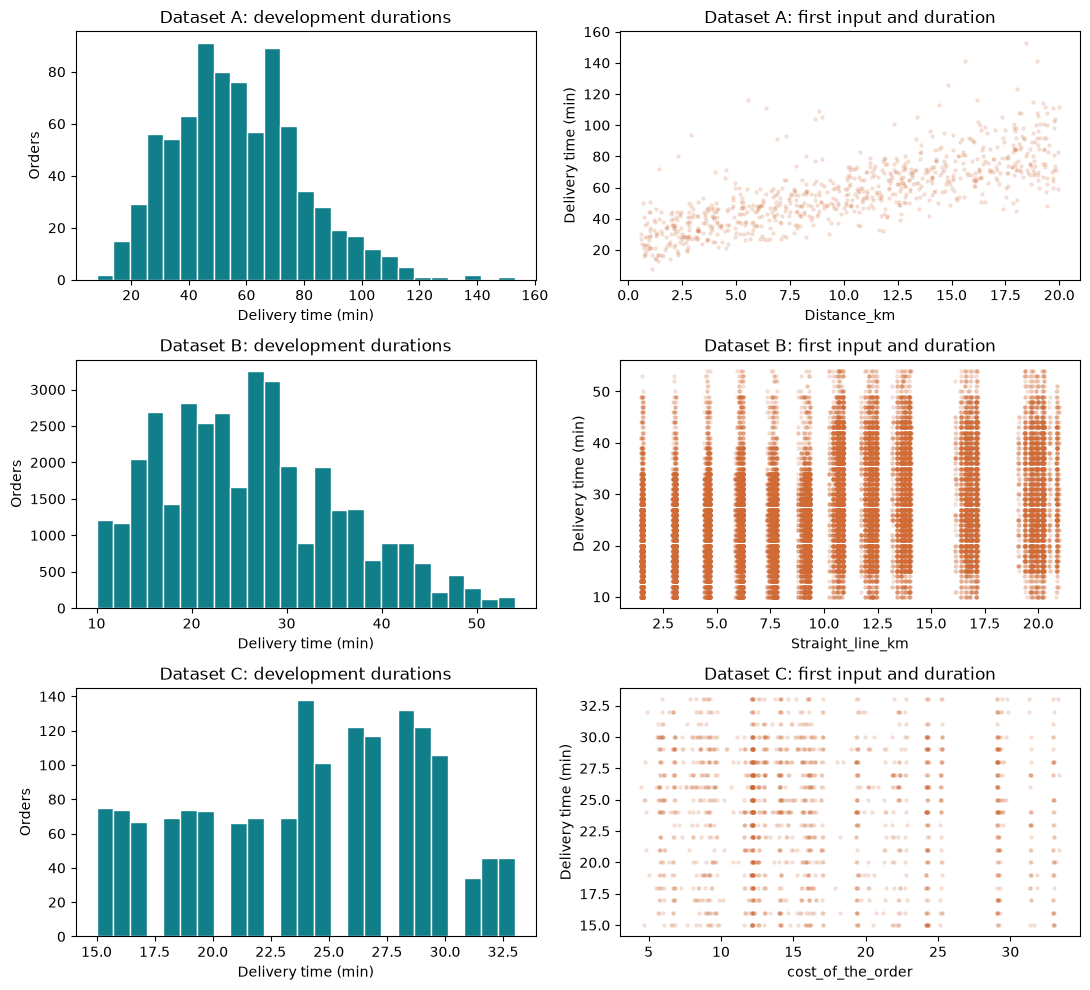

In [3]:
fig,axes=plt.subplots(3,2,figsize=(11,10))
for row,(key,e) in enumerate(experiments.items()):
    xx=e['X'].iloc[e['tr']]; yy=e['y'].iloc[e['tr']]
    display(xx.describe(include='all'));display(yy.describe())
    axes[row,0].hist(yy,bins=25,color='#117F89',edgecolor='white')
    axes[row,0].set(title=f'Dataset {key}: development durations',xlabel='Delivery time (min)',ylabel='Orders')
    axes[row,1].scatter(xx[e['nums'][0]],yy,s=5,alpha=.15,color='#D16B36')
    axes[row,1].set(title=f'Dataset {key}: first input and duration',xlabel=e['nums'][0],ylabel='Delivery time (min)')
fig.tight_layout();fig.savefig(RESULTS/'development_eda.png',dpi=160);plt.show()

## 6. Predictive modelling and validation
Four candidates use the same five partitions within each dataset: median baseline; Ridge (alpha 10); random forest (100 trees, minimum leaf size 5); histogram gradient boosting (200 iterations, learning rate 0.05, maximum 15 leaves, early stopping disabled). No extensive tuning or test-driven revisions are performed. Negative predictions are clipped to zero consistently.

MAE is mean absolute error: the average size of a prediction error in minutes. Lower is better. Fold standard deviation describes variability, not a confidence interval. A courier group split is stricter than mixing the same courier across training and validation.

C uses restaurant-group validation and the same four fixed candidates. No new settings are chosen after inspecting C test results.

In [4]:
candidates={
 'Median baseline':DummyRegressor(strategy='median'),
 'Ridge':Ridge(alpha=10),
 'Random forest':RandomForestRegressor(n_estimators=100,min_samples_leaf=5,random_state=SEED,n_jobs=2),
 'Gradient boosting':HistGradientBoostingRegressor(max_iter=200,max_leaf_nodes=15,learning_rate=.05,early_stopping=False,random_state=SEED)}
def pipeline(model,e):
    numeric=Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True)),('scale',StandardScaler())])
    category=Pipeline([('impute',SimpleImputer(strategy='constant',fill_value='Unknown')),('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False))])
    return Pipeline([('prepare',ColumnTransformer([('numeric',numeric,e['nums']),('categorical',category,e['cats'])])),('model',clone(model))])
cv_rows=[]; selected={}
with threadpool_limits(limits=2):
 for key,e in experiments.items():
    X=e['X'].iloc[e['tr']]; y=e['y'].iloc[e['tr']]
    for name,model in candidates.items():
        for fold,(tr,va) in enumerate(e['folds'],1):
            fit=pipeline(model,e).fit(X.iloc[tr],y.iloc[tr])
            pred=np.maximum(0,fit.predict(X.iloc[va]))
            cv_rows.append({'dataset':key,'model':name,'fold':fold,'MAE':mean_absolute_error(y.iloc[va],pred)})
        print(key,name,'finished',flush=True)
    temp=pd.DataFrame(cv_rows).query('dataset == @key').groupby('model').MAE.mean()
    selected[key]=temp.idxmin()
cv=pd.DataFrame(cv_rows)
cv.to_csv(RESULTS/'cv_folds.csv',index=False)
cv_summary=cv.groupby(['dataset','model']).MAE.agg(['mean','std']).reset_index().rename(columns={'mean':'CV_MAE','std':'CV_SD'})
cv_summary.to_csv(RESULTS/'cv_comparison.csv',index=False)
display(cv_summary.round(3));print('Selected using validation only:',selected)

A Median baseline finished


A Ridge finished


A Random forest finished


A Gradient boosting finished


B Median baseline finished


...

C Ridge finished


C Random forest finished


C Gradient boosting finished


,dataset,model,CV_MAE,CV_SD
0,A,Gradient boosting,10.490,0.643
1,A,Median baseline,17.916,0.600
2,A,Random forest,10.098,0.619
3,A,Ridge,9.376,0.509
4,B,Gradient boosting,6.502,0.050
5,B,Median baseline,7.559,0.067
6,B,Random forest,6.738,0.056
7,B,Ridge,6.753,0.048
8,C,Gradient boosting,3.615,0.114
9,C,Median baseline,4.159,0.074


Selected using validation only: {'A': 'Ridge', 'B': 'Gradient boosting', 'C': 'Gradient boosting'}


## 7. Final test evaluation and interpretation
Refit each selected model on all its development data, then score the reserved test data. RMSE penalizes larger errors; R-squared describes explained variation and is **not classification accuracy**. The percentage within 10 minutes is an observed tolerance rate, not an arrival-time guarantee.

Permutation importance measures how much test MAE rises after shuffling one input. It explains dependence of the frozen model and does not imply causation. No model selection follows this analysis. Save predictions, diagnostics, importance values, and complete pipelines for reproducibility.

Dataset A model: Ridge


,baseline,selected
MAE,17.465,8.568
RMSE,21.179,11.136
R2,-0.001,0.723
within_10_percent,31.500,66.500


,feature,MAE_increase,SD
0,Distance_km,12.788,0.647
2,Weather,1.163,0.099
3,Traffic_Level,1.027,0.303
1,Courier_Experience_yrs,0.279,0.080
4,Time_of_Day,0.010,0.064
5,Vehicle_Type,-0.039,0.027


Dataset B model: Gradient boosting


,baseline,selected
MAE,7.613,6.477
RMSE,9.522,8.044
R2,-0.022,0.271
within_10_percent,74.275,78.617


,feature,MAE_increase,SD
0,Straight_line_km,0.994,0.017
1,Delivery_person_Age,0.990,0.015
3,Type_of_vehicle,0.208,0.018
2,Type_of_order,0.001,0.002


Dataset C model: Gradient boosting


,baseline,selected
MAE,4.275,3.640
RMSE,5.082,4.358
R2,-0.031,0.242
within_10_percent,100.000,100.000


,feature,MAE_increase,SD
2,day_of_the_week,1.365,0.194
0,cost_of_the_order,-0.063,0.077
1,cuisine_type,-0.081,0.039


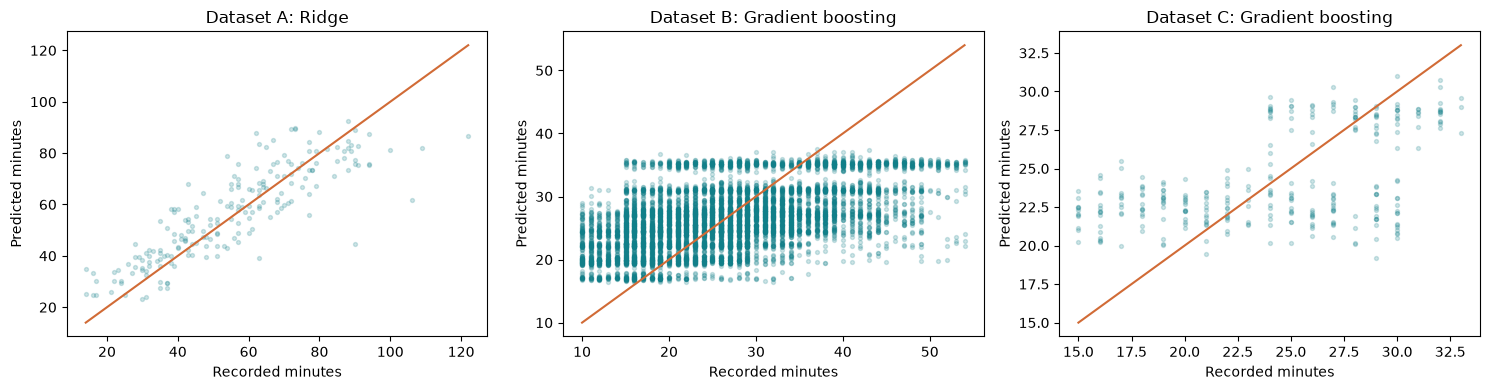

4453

In [5]:
def metrics(y,p):
    return {'MAE':float(mean_absolute_error(y,p)),'RMSE':float(np.sqrt(mean_squared_error(y,p))),
            'R2':float(r2_score(y,p)),'within_10_percent':float(np.mean(np.abs(y-p)<=10)*100)}
summary={'datasets':{},'versions':versions,'seed':SEED}; metric_rows=[]
fig,axes=plt.subplots(1,3,figsize=(15,4))
with threadpool_limits(limits=2):
 for i,(key,e) in enumerate(experiments.items()):
    Xtr=e['X'].iloc[e['tr']]; yt=e['y'].iloc[e['tr']]
    Xte=e['X'].iloc[e['te']]; yte=e['y'].iloc[e['te']]
    fit=pipeline(candidates[selected[key]],e).fit(Xtr,yt)
    pred=np.maximum(0,fit.predict(Xte))
    baseline=pipeline(candidates['Median baseline'],e).fit(Xtr,yt)
    bm=metrics(yte,np.maximum(0,baseline.predict(Xte))); tm=metrics(yte,pred)
    train=metrics(yt,np.maximum(0,fit.predict(Xtr)))
    joblib.dump(fit,ROOT/f'models/model_{key}.joblib')
    reloaded=joblib.load(ROOT/f'models/model_{key}.joblib')
    np.testing.assert_allclose(reloaded.predict(Xte),fit.predict(Xte))
    source=e['clean'].iloc[e['te']]
    pd.DataFrame({'source_row':source.index,'actual_min':yte.values,'predicted_min':pred,'absolute_error':np.abs(yte.values-pred)}).to_csv(RESULTS/f'{key}_predictions.csv',index=False)
    pi=permutation_importance(fit,Xte,yte,scoring='neg_mean_absolute_error',n_repeats=5,random_state=SEED,n_jobs=1)
    importance=pd.DataFrame({'feature':Xte.columns,'MAE_increase':pi.importances_mean,'SD':pi.importances_std}).sort_values('MAE_increase',ascending=False)
    importance.to_csv(RESULTS/f'{key}_importance.csv',index=False)
    source.iloc[:1].drop(columns=[e['target']]).to_csv(ROOT/f'data/example_{key}.csv',index=False)
    example=float(np.maximum(0,reloaded.predict(prepare_features(source.iloc[:1],key)))[0])
    summary['datasets'][key]={'audit':audits[key],'selected_model':selected[key],'test':tm,'baseline':bm,'train':train,
        'improvement_percent':float((bm['MAE']-tm['MAE'])/bm['MAE']*100),
        'example_predicted':example,'example_actual':float(yte.iloc[0]),'top_feature':str(importance.iloc[0].feature)}
    for name,m in [('Median baseline',bm),(selected[key],tm)]:metric_rows.append({'dataset':key,'model':name,**m})
    axes[i].scatter(yte,pred,s=8,alpha=.2,color='#117F89')
    lo=min(yte.min(),pred.min());hi=max(yte.max(),pred.max())
    axes[i].plot([lo,hi],[lo,hi],color='#D16B36');axes[i].set(title=f'Dataset {key}: {selected[key]}',xlabel='Recorded minutes',ylabel='Predicted minutes')
    print('Dataset',key,'model:',selected[key]);display(pd.DataFrame({'baseline':bm,'selected':tm}).round(3));display(importance.round(3))
fig.tight_layout();fig.savefig(RESULTS/'test_predictions.png',dpi=160);plt.show()
pd.DataFrame(metric_rows).to_csv(RESULTS/'test_metrics.csv',index=False)
(RESULTS/'summary.json').write_text(json.dumps(summary,indent=2))

## 8. Conclusions, limitations and reuse
The same KDD process now operates on **all three Kaggle datasets**, with separate feature sets and saved models. Read the executed summary below for measured results. Differences in error do not prove one dataset or algorithm is universally better: duration distributions, inputs and split rules differ. B tests unseen couriers and C tests unseen restaurants. A lacks entity IDs. None provides reliable event dates for a future-period test.

Dataset B quality rules are assumptions that can affect results. Its 100-km straight-line threshold is a plausibility screen, not a road-distance guarantee. Delivery-person age is included as a descriptive covariate, not for employment decisions. Rating was omitted due to timing ambiguity. Collection provenance and exact duration endpoints are not fully documented. A real deployment needs verified order-time features, timestamped data, road routing, fairness assessment and calibrated time ranges.

Run `python predict.py --dataset A --input data/example_A.csv --output results/demo_A.csv` (or B or C). Each saved pipeline expects its own engineered schema; `features.py` performs deterministic preparation first. The script never needs a target value.

## 9. References
1. Den_Kuznetz. Food Delivery Time Prediction. Kaggle. https://www.kaggle.com/datasets/denkuznetz/food-delivery-time-prediction
2. Rajat Kumar. Food Delivery Time. Kaggle. https://www.kaggle.com/datasets/rajatkumar30/food-delivery-time
3. Garg et al. (2025). Food Delivery Time Prediction in Indian Cities Using Machine Learning Models. https://arxiv.org/abs/2503.15177
4. Wen et al. (2023). A Survey on Service Route and Time Prediction in Instant Delivery. https://arxiv.org/abs/2309.01194
5. scikit-learn. Cross-validation and grouped data. https://scikit-learn.org/stable/modules/cross_validation.html
6. scikit-learn. Pipelines. https://scikit-learn.org/stable/modules/compose.html
7. scikit-learn. Permutation importance. https://scikit-learn.org/stable/modules/permutation_importance.html

Dataset A: Apache 2.0 per Kaggle metadata. Dataset B: Open Database License with Database Contents License per Kaggle metadata. Bundled source metadata, raw data and license links provide attribution.

8. Ahsan Raza. NYC Restaurants Data - Food Ordering and Delivery. Kaggle, version 1. https://www.kaggle.com/datasets/ahsan81/food-ordering-and-delivery-app-dataset

C's `delivery_time` excludes preparation. This experiment estimates the delivery stage and cannot be used as a total order-to-door ETA without a separate preparation estimate. C has limited predictors and no distance/traffic fields. Restaurant-group splitting still permits the same customer to occur in both partitions, so no unseen-customer claim is made. Dataset C metadata lists CC0: https://creativecommons.org/publicdomain/zero/1.0/ .


In [6]:
for key,s in summary['datasets'].items():
    print(f"Dataset {key}: {s['selected_model']}; test MAE {s['test']['MAE']:.2f} min; baseline MAE {s['baseline']['MAE']:.3f} min; reduction {s['improvement_percent']:.1f}%.")
    print(f"Example: predicted {s['example_predicted']:.2f} min; recorded {s['example_actual']:.2f} min.")
print('All three pipelines saved; reload predictions verified. No test-set tuning performed.')

Dataset A: Ridge; test MAE 8.57 min; baseline MAE 17.465 min; reduction 50.9%.
Example: predicted 37.62 min; recorded 32.00 min.
Dataset B: Gradient boosting; test MAE 6.48 min; baseline MAE 7.613 min; reduction 14.9%.
Example: predicted 27.08 min; recorded 36.00 min.
Dataset C: Gradient boosting; test MAE 3.64 min; baseline MAE 4.275 min; reduction 14.8%.
Example: predicted 22.25 min; recorded 20.00 min.
All three pipelines saved; reload predictions verified. No test-set tuning performed.
